# Warcraft III — класификатор на единици

Проектът следва **Lesson 1** ("Is it a bird?") и **Lesson 2** (production, Gradio, Hugging Face) от курса
[Practical Deep Learning for Coders](https://course.fast.ai/) на Jeremy Howard
(и избора на модел от **Lesson 3**).

Моделът разпознава **8 единици** от Warcraft III — по две от всяка раса:

| Раса | Единици |
|---|---|
| Human | Footman, Rifleman |
| Orc | Grunt, Troll Headhunter |
| Night Elf | Archer, Huntress |
| Undead | Ghoul, Crypt Fiend |

Стъпки: **1)** търсим и сваляме снимки → **2)** чистим данните → **3)** обучаваме модел →
**4)** гледаме грешките → **5)** експортираме модела за Gradio приложението (`app.py`).

In [1]:
from fastai.vision.all import *
from ddgs import DDGS
import hashlib, time

C:\Users\bobi\Desktop\warcraft3-classifier\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Сваляне на изображения

Както в Lesson 1, търсим картинки в DuckDuckGo. Името на всяка папка е името на класа (етикета).
Към всяко търсене добавяме "warcraft 3", за да не получим например истински стрелци или герои от World of Warcraft.

In [2]:
def search_images(term, max_images=50):
    print(f"Searching for '{term}'")
    return L(DDGS().images(term, max_results=max_images)).itemgot('image')

In [3]:
units = ['Human Footman', 'Human Rifleman',
         'Orc Grunt', 'Troll Headhunter',
         'Night Elf Archer', 'Night Elf Huntress',
         'Undead Ghoul', 'Undead Crypt Fiend']
searches = ['warcraft 3 {}', 'warcraft 3 {} model', 'warcraft 3 {} reforged', 'wc3 {}', 'warcraft iii {} unit',
            'warcraft 3 {} screenshot', 'warcraft 3 {} art', 'warcraft 3 {} portrait', 'warcraft 3 {} attack', 'warcraft 3 {} 3d']
path = Path('data')

In [4]:
for unit in units:
    dest = path/unit
    if dest.exists(): continue          # вече е свалено - не търсим пак
    dest.mkdir(parents=True)
    for s in searches:
        download_images(dest, urls=search_images(s.format(unit)))
        time.sleep(5)                    # пауза, за да не ни блокира търсачката
    resize_images(dest, max_size=400, dest=dest)

## 2. Почистване на данните

Махаме файловете, които не са валидни картинки (`verify_images`), и точните дубликати —
една и съща снимка може да се появи в няколко търсения. Ако остане в train и в validation,
резултатът ще изглежда по-добър, отколкото е.

**Най-важната стъпка в този проект беше ръчното почистване.** Търсачката връща и много боклук:
цели екрани от играта, YouTube заглавни картинки, други единици. Първият модел, обучен върху всичко
свалено, грешеше в **52%** от случаите. След като махнахме лошите снимки (виж `ImageClassifierCleaner`
по-долу), същият `resnet18` грешеше в **26%** — без да сменяме нищо в кода. Както казва Jeremy в Lesson 2:
данните са по-важни от модела.

In [5]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
print('Broken images removed:', len(failed))

seen = set()
for f in get_image_files(path):
    h = hashlib.md5(f.read_bytes()).hexdigest()
    if h in seen: f.unlink()
    else: seen.add(h)

for unit in units: print(unit, len(get_image_files(path/unit)))

Broken images removed: 0
Human Footman 51
Human Rifleman 40
Orc Grunt 80
Troll Headhunter 65
Night Elf Archer 47
Night Elf Huntress 30
Undead Ghoul 70
Undead Crypt Fiend 37


## 3. DataLoaders

`DataBlock` казва на fastai:
- **blocks** — входът е картинка, изходът е категория;
- **get_items** — откъде да вземе файловете;
- **splitter** — 20% от снимките остават настрана за проверка (validation);
- **get_y** — етикетът е името на папката;
- **item_tfms** — всяка картинка става 224×224;
- **batch_tfms** — augmentation: леки завъртания, zoom, осветление (Lesson 2).

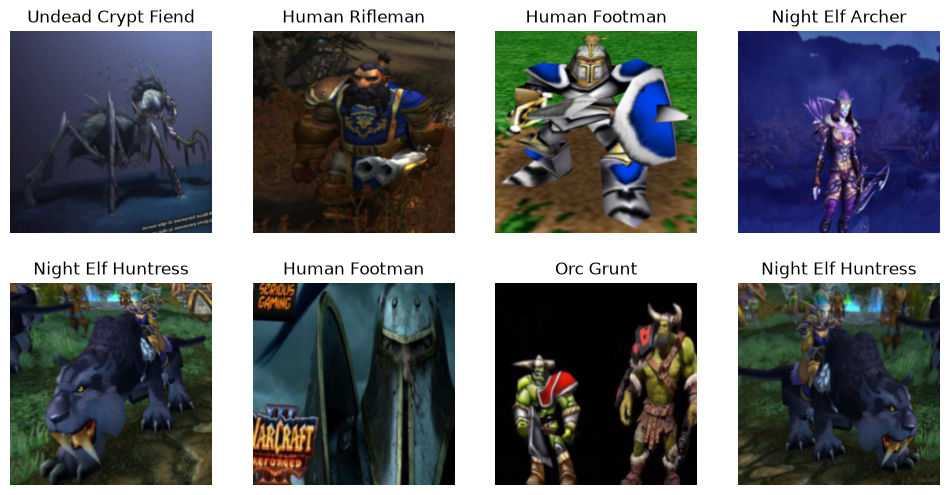

In [6]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=get_image_files,
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=Resize(224, method='squish'),
    batch_tfms=aug_transforms()
).dataloaders(path, bs=32)

dls.show_batch(max_n=8)

## 4. Обучение

Използваме **transfer learning**: моделът вече е обучен предварително върху милиони снимки (ImageNet).
`fine_tune` първо обучава само последния слой (1 epoch), а после донастройва цялата мрежа.

Кой модел? В **Lesson 3** ("Which image models are best?") Jeremy препоръчва `convnext_tiny` вместо `resnet`.
Пробвахме три модела върху едни и същи данни:

| Модел | error_rate |
|---|---|
| `resnet18` (като в Lesson 1) | 26% |
| `resnet34` | 21% |
| `convnext_tiny_in22k` (Lesson 3) | **14–18%** |

`convnext` моделите идват от библиотеката `timm` (`pip install timm`), затова името е в кавички.

Validation set-ът е само 84 снимки, затова резултатът се мени с няколко процента при всяко обучение (в този notebook: 17.9%).

In [7]:
learn = vision_learner(dls, 'convnext_tiny_in22k', metrics=error_rate)
learn.fine_tune(6)

C:\Users\bobi\Desktop\warcraft3-classifier\.venv\Lib\site-packages\timm\models\_factory.py:175: UserWarning: Mapping deprecated model name convnext_tiny_in22k to current convnext_tiny.fb_in22k.
  model = create_fn(


epoch,train_loss,valid_loss,error_rate,time
0,3.112174,1.775553,0.583333,02:51


epoch,train_loss,valid_loss,error_rate,time
0,1.333560,1.135062,0.380952,03:43
1,1.093351,0.802052,0.333333,03:38
2,0.828807,0.712354,0.238095,03:47
3,0.661663,0.592018,0.202381,05:04
4,0.524225,0.540775,0.178571,04:32
5,0.458529,0.525380,0.178571,04:23


## 5. Къде греши моделът?

**Confusion matrix** — по диагонала са верните отговори, извън него са грешките.
**Top losses** — снимките, при които моделът е най-сигурен, но греши, или е най-несигурен.
Често това са лоши данни (грешна картинка от търсачката), а не грешка на модела.

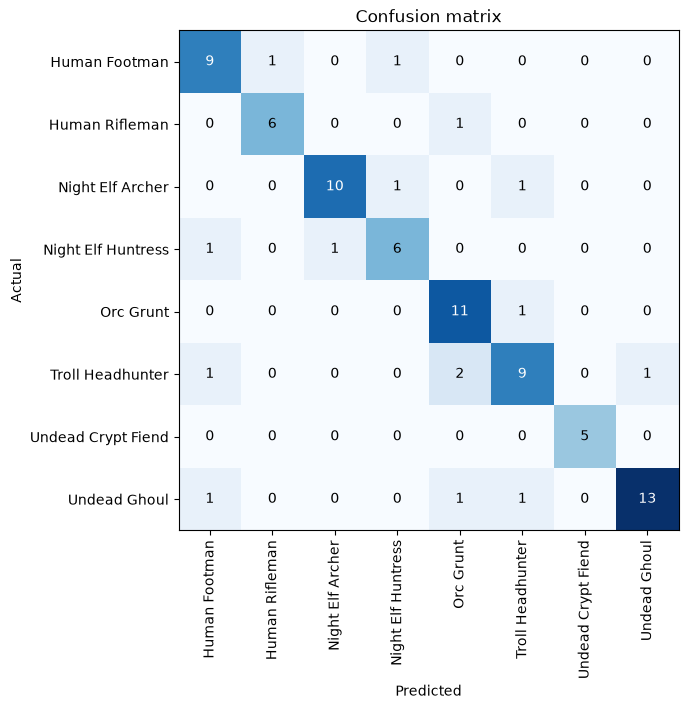

In [8]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix(figsize=(7,7))

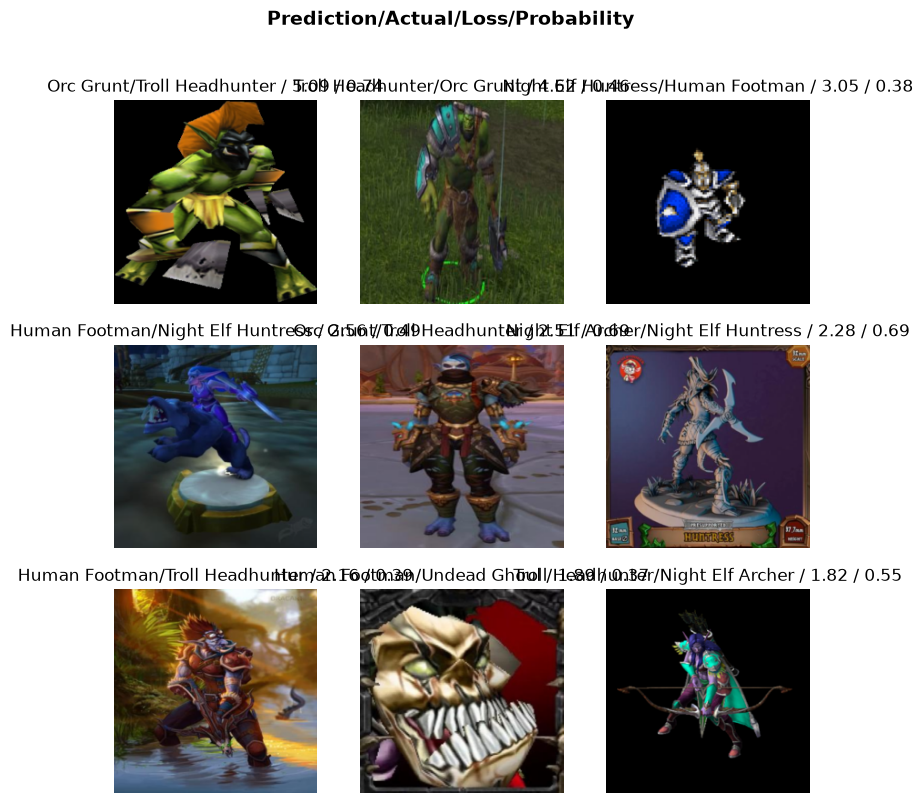

In [9]:
interp.plot_top_losses(9, nrows=3)

### По желание: ръчно почистване (Lesson 2)

`ImageClassifierCleaner` показва снимките с най-голяма грешка. За всяка можете да изберете
**<Delete>** или правилния клас. После пуснете следващата клетка и обучете модела отново (секция 3 и 4).

In [10]:
from fastai.vision.widgets import ImageClassifierCleaner
cleaner = ImageClassifierCleaner(learn)
cleaner

In [11]:
for idx in cleaner.delete(): cleaner.fns[idx].unlink()
for idx, cat in cleaner.change(): shutil.move(str(cleaner.fns[idx]), path/cat)

## 6. Export

Записваме модела в един файл — `model.pkl`. Него качваме в Hugging Face Space заедно с `app.py`.

In [12]:
learn.export('model.pkl')

## 7. Проверка: зареждаме модела като в `app.py`

C:\Users\bobi\Desktop\warcraft3-classifier\.venv\Lib\site-packages\fastai\learner.py:456: UserWarning: load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.
  warn("load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.\nIf you only need to load model weights and optimizer state, use the safe `Learner.load` instead.")


This is a: Orc Grunt  (100%)


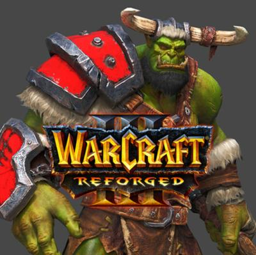

In [13]:
learn = load_learner('model.pkl')
img = get_image_files(path/'Orc Grunt')[0]
unit, _, probs = learn.predict(PILImage.create(img))
print(f'This is a: {unit}  ({probs.max():.0%})')
PILImage.create(img).to_thumb(256)

## 8. Export за браузъра (GitHub Pages)

Безплатният план на Hugging Face вече не пуска Gradio Spaces, затова моделът работи **директно в браузъра**
на посетителя, а сайтът е в GitHub Pages (`docs/index.html`).

- **ONNX** е общ формат за невронни мрежи — PyTorch моделът се записва така, че да може да го пусне и JavaScript
  (с библиотеката `onnxruntime-web`).
- **Quantization** (int8) смалява модела от ~115 MB на ~35 MB — GitHub не приема файлове над 100 MB,
  а и сайтът се зарежда по-бързо. Цената е малка: на validation set-а точността падна от 82.1% на 81.0%
  (една снимка от 84).
- Страницата прави същата подготовка като fastai: преоразмерява до 224×224 (squish), дели на 255 и нормализира
  с ImageNet средните стойности.

In [14]:
import json
from onnxruntime.quantization import quantize_dynamic, QuantType

learn.model.eval().cpu()
torch.onnx.export(learn.model, torch.randn(1, 3, 224, 224), 'model.onnx',
                  input_names=['image'], output_names=['logits'], dynamo=False)
quantize_dynamic('model.onnx', 'docs/model.onnx', weight_type=QuantType.QInt8,
                 op_types_to_quantize=['MatMul', 'Gemm'], per_channel=True)
Path('docs/model.json').write_text(json.dumps({
    'labels': list(learn.dls.vocab), 'multi_label': False, 'height': 224, 'width': 224,
    'examples': sorted(f.name for f in Path('docs/examples').glob('*.jpg'))}))

for f in ['model.pkl', 'model.onnx', 'docs/model.onnx']: print(f, Path(f).stat().st_size // 1_000_000, 'MB')

model.pkl 114 MB
model.onnx 114 MB
docs/model.onnx 34 MB
